# Minjae Kyung CS373 Final Project

이 프로젝트는 주식 데이터와 뉴스 데이터, 그리고 주요 뉴스 데이터를 이용하여 주식의 변동성을 파악하여 주어진 주식종목의 포트폴리오를 생성하는 모델을 제작하는 것이 목표인 프로젝트로서 이를 위해 트랜스포머와 PPO를 활용하여 모델을 구성하여 과거의 시계열을 이해하고 이를 이용하여 스스로 행동하고 평가하여 더 나은 결과를 얻도록 모델을 설계하였다.

## Import Modules

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast
from stable_baselines3 import PPO

from source.stock_portfolio_env import PortfolioEnv
from source.portfolio_feature_extractor import PortfolioFeatureExtractor
from stable_baselines3.common.logger import configure

%load_ext autoreload
%autoreload 1
%aimport source.stock_portfolio_env
%aimport source.portfolio_feature_extractor

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data Preparation

먼저 데이터를 생성하기 위해 yfinanace 모듈을 통해 특정 회사의 주식정보를 모은다음, 그 주식과 관련된 키워드의 GDELT의 DOC 2.0 API를 이용하여 그 데이터의 링크를 가져오고, 그 링크에 있는 내용을 크롤링 한다음 그 내용 데이터를 Gemini-embedding을 이용해 임베딩 하여 데이터를 준비하였다.

프레젠테이션에서 말했듯이 데이터를 구하는데 많은 어려움을 겪어 일단 이번 실험에서는 apple의 데이터만 사용하여 프로젝트를 진행해 보도록 하겠다.

트레인 기간은 내가 데이터를 구할 수 있었던 2017-01-04 부터 2024-12-31로 하고, 테스트 기간은 글로벌 뉴스를 가장 최근까지 얻을 수 있었던 2025-03-23으로 해주도록 하겠다.

In [2]:
DATE_FULL_SLICE = slice("2017-01-04", "2025-03-20")
DATE_TRAIN_SLICE = slice("2017-01-04", "2024-12-31")
DATE_TEST_SLICE = slice("2025-01-01", "2025-03-20")

## Stock Market Data

먼저 yfinance를 통해 얻어온 주식 데이터를 정제해 주도록 하겠다.

In [3]:
# header=[0, 1]: 첫 번째와 두 번째 행을 모두 컬럼명(헤더)으로 사용
apple_stock_df = pd.read_csv('./data_stocks/AAPL_stock.csv', header=[0, 1], index_col=0)

# 'Date' 행 제거 그리고 읽어온 직후 첫 번째 행이 전부 NaN이라면 제거합니다.
if apple_stock_df.iloc[0].isnull().all():
    apple_stock_df = apple_stock_df.iloc[1:]

# 인덱스를 날짜 형식으로 변환
apple_stock_df.index = pd.to_datetime(apple_stock_df.index)

display(apple_stock_df.head())

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
1995-12-08,0.295225,0.295225,0.283978,0.290538,141355200
1995-12-11,0.289601,0.297099,0.287727,0.296162,111652800
1995-12-12,0.284915,0.289601,0.284915,0.289601,177553600
1995-12-13,0.287727,0.292412,0.275543,0.286789,684902400
1995-12-14,0.286790,0.295225,0.284915,0.291475,333502400


현재 뉴스 정보를 얻을 수 있던 2017년 이전의 정보는 내가 설계한 모델에 학습 시킬 수 없으므로 2017년 이후로 필터링 해주도록 하겠다.

In [4]:
apple_stock_df = apple_stock_df.loc['2017':]
apple_stock_df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2017-01-03,26.770884,26.812371,26.450509,26.690214,115127600
2017-01-04,26.740919,26.853858,26.678689,26.701737,84472400
2017-01-05,26.876911,26.934533,26.692522,26.717876,88774400
2017-01-06,27.176537,27.234158,26.844637,26.916087,127007600
2017-01-09,27.425461,27.526875,27.183452,27.185756,134247600
...,...,...,...,...,...
2025-11-21,271.489990,273.329987,265.670013,265.950012,59030800
2025-11-24,275.920013,277.000000,270.899994,270.899994,65585800


그리고 이 주식정보를 ML이 더 잘 이해할 수 있도록 값을 변환해주도록 하겠다.

In [5]:
close_prev = apple_stock_df["Close"].shift(1)
volume_prev = apple_stock_df["Volume"].shift(1)
eps = 1e-8  # 작은 상수로 나누기 오류 방지

apple_stock_refined_df =  pd.DataFrame(index=apple_stock_df.index)

# 1. 전일 종가 대비 종가 로그수익률
apple_stock_refined_df["ret_close"] = np.log((apple_stock_df["Close"] + eps) / (close_prev + eps))

# 2. 전일 종가 대비 시가 갭
apple_stock_refined_df["gap"] = np.log((apple_stock_df["Open"] + eps) / (close_prev + eps))

# 3. 시가 대비 종가 수익률
apple_stock_refined_df["intraday_ret"] = np.log((apple_stock_df["Close"] + eps) / (apple_stock_df["Open"] + eps))

# 4. 고가/저가 변동폭
apple_stock_refined_df["hl_range"] = np.log((apple_stock_df["High"] + eps) / (apple_stock_df["Low"] + eps))

# 5. 고-저 사이에서 종가 위치 (0~1)
apple_stock_refined_df["close_pos"] = (apple_stock_df["Close"] - apple_stock_df["Low"]) / (apple_stock_df["High"] - apple_stock_df["Low"] + eps)

# 6. 로그 거래량
apple_stock_refined_df["log_volume"] = np.log(apple_stock_df["Volume"] + 1.0)

# 7. 거래량 변화율 (로그 비율)
apple_stock_refined_df["vol_change"] = np.log((apple_stock_df["Volume"] + 1.0) / (volume_prev + 1.0))

지금 이 변환으로 인해 맨 첫번째 행에 nan값들이 생겼고, 이로 인해 맨 첫번째 행은 쓸 수 없게 되었으니 없애주도록 하겠다. 그리고 이것이 우리의 데이터의 시작 날짜가 결정된 이유이다.

In [6]:
apple_stock_refined_df = apple_stock_refined_df.dropna()
apple_stock_refined_df = apple_stock_refined_df.loc[DATE_FULL_SLICE]
apple_stock_refined_df

,ret_close,gap,intraday_ret,hl_range,close_pos,log_volume,vol_change
Date,,,,,,,
2017-01-04,-0.001120,-0.002586,0.001466,0.006544,0.355258,18.251935,-0.309616
2017-01-05,0.005073,-0.000862,0.005935,0.009026,0.761905,18.301609,0.049673
2017-01-06,0.011086,0.001457,0.009630,0.014406,0.852071,18.659757,0.358149
2017-01-09,0.009118,0.000339,0.008779,0.012554,0.704696,18.715196,0.055439
2017-01-10,0.001008,-0.001851,0.002859,0.009088,0.750002,18.398930,-0.316267
...,...,...,...,...,...,...,...
2025-03-14,0.018007,0.007460,0.010548,0.020637,0.894739,17.911647,-0.020757
2025-03-17,0.002386,-0.000844,0.003230,0.024696,0.767619,17.688240,-0.223407
2025-03-18,-0.006140,0.000747,-0.006888,0.017158,0.327869,17.563423,-0.124817


그리고 이제 이 데이터를 시간을 기준으로 2025년 이전 데이터는 train용으로, 2025년 데이터는 test용으로 분리하도록 하겠다.

In [7]:
apple_stock_train = np.array(apple_stock_refined_df.loc[DATE_TRAIN_SLICE])
apple_close_prices_train = np.array(apple_stock_df.loc[DATE_TRAIN_SLICE]["Close"])

apple_stock_test = np.array(apple_stock_refined_df.loc[DATE_TEST_SLICE])
apple_close_prices_test = np.array(apple_stock_df.loc[DATE_TEST_SLICE]["Close"])

In [8]:
print("Train shape:", apple_stock_train.shape)
print(apple_stock_train)

print("Test shape:", apple_stock_test.shape)
print(apple_stock_test)

Train shape: (2011, 7)
[[-1.11991929e-03 -2.58624269e-03  1.46632340e-03 ...  3.55257722e-01
   1.82519354e+01 -3.09616222e-01]
 [ 5.07265367e-03 -8.62102879e-04  5.93475655e-03 ...  7.61905422e-01
   1.83016089e+01  4.96734658e-02]
 [ 1.10863776e-02  1.45653734e-03  9.62984024e-03 ...  8.52071198e-01
   1.86597575e+01  3.58148604e-01]
 ...
 [-1.33305987e-02 -4.60478152e-03 -8.72581715e-03 ...  4.48580178e-01
   1.75616041e+01  4.41513533e-01]
 [-1.33521898e-02 -1.32332485e-02 -1.18941299e-04 ...  5.27271616e-01
   1.73866617e+01 -1.74942452e-01]
 [-7.08286317e-03  9.51242290e-04 -8.03410546e-03 ...  2.57143876e-01
   1.74913225e+01  1.04660838e-01]]
Test shape: (53, 7)
[[-2.65862312e-02 -5.96783539e-03 -2.06183958e-02  2.96607687e-02
   2.78846033e-01  1.78362212e+01  3.44898628e-01]
 [-2.01151309e-03 -2.01151309e-03  0.00000000e+00  9.42255340e-03
   6.41923810e-01  1.75104740e+01 -3.25747164e-01]
 [ 6.71649963e-03  3.89618980e-03  2.82030983e-03  1.68393472e-02
   4.35835574e-01  1.

그리고 정제한 데이터를 나중에 쓸수도 있으니 일단 저장해 놓도록 하겠다.

In [9]:
apple_stock_refined_df.to_csv('./data_stocks/AAPL_stock_refined.csv')

### Apple Stock News Data

이제 이 애플의 주식을 분석하는데 사용할 뉴스 데이터를 불러오도록 하겠다.

In [ ]:
apple_stock_news_df = pd.read_csv('./data_news_pipeline/step2_content/AAPL_content.csv', index_col=0)
apple_stock_news_df_cleaned = apple_stock_news_df[~apple_stock_news_df.isna().any(axis=1)] # 결측치가 있는 행 제거
apple_stock_news_df_cleaned.index = pd.to_datetime(apple_stock_news_df_cleaned.index) # 인덱스를 날짜 형식으로 변환
apple_stock_news_df_cleaned = apple_stock_news_df_cleaned.sort_index() # 인덱스 기준 정렬
apple_stock_news_df_cleaned = apple_stock_news_df_cleaned[:"2025-11-01"] # 2025-11-01까지 데이터 필터링

In [11]:
apple_stock_news_df_cleaned

,Title,Media,Link,FullText
Date,,,,
2017-01-01,"Nwam LLC Has $8 , 159 , 000 Stake in Apple Inc...",mideasttime.com,http://www.mideasttime.com/nwam-llc-has-815900...,Menelusuri dunia situs game online terpercaya ...
2017-01-02,APPLE IPHONE 7 PLUS 256GB,mouthshut.com,http://www.mouthshut.com/review/Apple-iPhone-7...,Iphone is a line of smart phone design and mar...
2017-01-02,Apple partner Wistron seeks to expand India sm...,thestar.com.my,http://www.thestar.com.my/business/business-ne...,MUMBAI: Smartphone component maker Wistron Cor...
2017-01-02,Apple partner Wistron seeks to expand India sm...,otcstockexchange.com,http://otcstockexchange.com/apple-partner-wist...,Acquiring OakvilleMaids.com through HugeDomain...
2017-01-02,Apple Inc . ( NASDAQ : AAPL ) Broker Price Tar...,fiscalstandard.com,http://www.fiscalstandard.com/2017/01/02/apple...,Name Properties\n\nLength 14\n\nTLD com\n\nReg...
...,...,...,...,...
2025-10-31,Jim Cramer Says Apple Bears Owe Us An Explana...,benzinga.com,https://www.benzinga.com/markets/tech/25/10/48...,"On Thursday, Apple Inc. (NASDAQ:AAPL) delivere..."
2025-10-31,Los Altos history : See the 1905 J . Gilbert S...,mercurynews.com,https://www.mercurynews.com/2025/10/31/los-alt...,If time travel were possible and you were zapp...
2025-11-01,Big Tech stubborn winning streak seems to be h...,latimes.com,https://www.latimes.com/business/story/2025-10...,A record-smashing rally in megacap high-fliers...


그리고 뉴스들이 날짜별로 잘 분포되어 있는지 확인해 보겠다.

#### Check Data

In [147]:
daily_counts = apple_stock_news_df_cleaned.resample('D').size()

print(daily_counts.describe())

count    3227.000000
mean       14.428881
std        12.949499
min         0.000000
25%         5.000000
50%        12.000000
75%        21.000000
max       242.000000
dtype: float64


describe로 보기에는 최댓값에 이상한 242가 있는거 말고는 25%부터 75%까지 비교적 적당하게 분포가 되어있다고 생각된다. 일단 더 자세하게 보기위해 히스토그램을 그려보도록 하겠다.

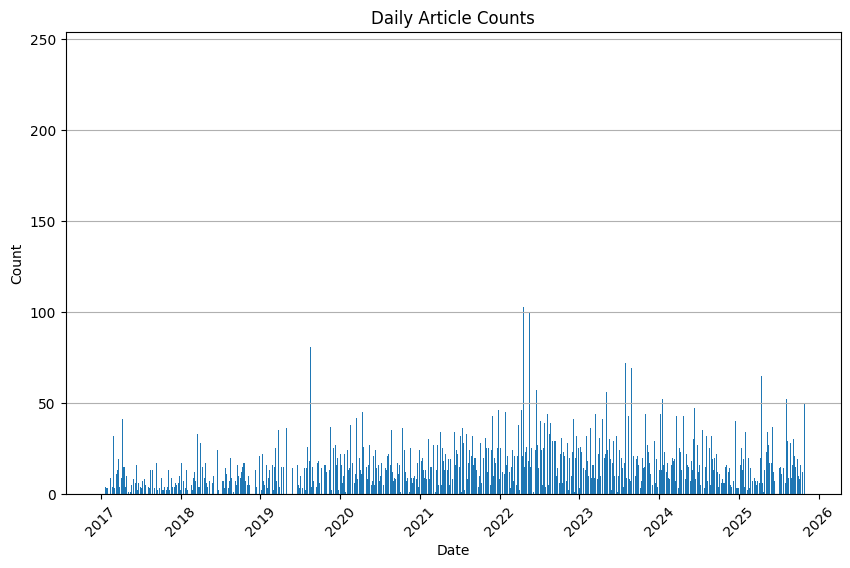

In [13]:
# 1. 날짜별 개수 구하기
daily_counts = apple_stock_news_df_cleaned.index.value_counts().sort_index()

# 2. 그래프 그리기
plt.figure(figsize=(10, 6))  # 그래프 크기 설정 (가로, 세로)
plt.bar(daily_counts.index, daily_counts.values)

# 3. 꾸미기 (옵션)
plt.title('Daily Article Counts') # 제목
plt.xlabel('Date')                # x축 라벨
plt.ylabel('Count')               # y축 라벨
plt.xticks(rotation=45)           # 날짜가 겹치지 않게 45도 회전
plt.grid(axis='y')                # y축 그리드 선 추가

plt.show()

다행히 고루고루 분포되어 있는듯 하다. 242개의 주인공은 너무 얇아서 보이지 않지만 이정도면 굳이 더 정제할 필요 없이 진행해도 될거 같다. 어차피 임베딩들의 평균을 구할 것이기 때문에 갯수차이가 많이 나는건 크게 상관 없을 듯 하다.

In [14]:
apple_stock_news_df_cleaned.to_csv('./data_news_pipeline/step3_clean/AAPL_content_cleaned.csv')

#### Embedding

이제 임베딩을 make_embedding.py에서 진행한 다음 다시 csv를 불러오도록 하겠다.

In [149]:
apple_stock_news_embedded_df = pd.read_csv('./data_news_pipeline/step4_embedding/AAPL_embedded.csv', index_col=0)
apple_stock_news_embedded_df.index = pd.to_datetime(apple_stock_news_embedded_df.index) # 인덱스를 날짜 형식으로 변환
apple_stock_news_embedded_df = apple_stock_news_embedded_df.sort_index() # 인덱스 기준 정렬

apple_stock_news_embedded_df.index = pd.to_datetime(apple_stock_news_embedded_df.index) # 인덱스를 날짜 형식으로 변환

apple_stock_news_embedded_df["embedding"] = apple_stock_news_embedded_df["embedding"].apply(ast.literal_eval) # 문자열로 저장되어 있는 임베딩 벡터를 리스트로 변환
apple_stock_news_embedded_df.head()

,Title,Media,Link,FullText,embedding
Date,,,,,
2017-01-01,"Nwam LLC Has $8 , 159 , 000 Stake in Apple Inc...",mideasttime.com,http://www.mideasttime.com/nwam-llc-has-815900...,Menelusuri dunia situs game online terpercaya ...,"[-0.012577439, -0.024079252, 0.0044829804, -0...."
2017-01-02,APPLE IPHONE 7 PLUS 256GB,mouthshut.com,http://www.mouthshut.com/review/Apple-iPhone-7...,Iphone is a line of smart phone design and mar...,"[-0.017085219, -0.00029014514, 0.010020777, -0..."
2017-01-02,Apple partner Wistron seeks to expand India sm...,thestar.com.my,http://www.thestar.com.my/business/business-ne...,MUMBAI: Smartphone component maker Wistron Cor...,"[-0.013036417, 0.005417432, -0.0069397204, -0...."
2017-01-02,Apple partner Wistron seeks to expand India sm...,otcstockexchange.com,http://otcstockexchange.com/apple-partner-wist...,Acquiring OakvilleMaids.com through HugeDomain...,"[-0.02031213, -0.0048704566, 0.00731049, -0.04..."
2017-01-02,Apple Inc . ( NASDAQ : AAPL ) Broker Price Tar...,fiscalstandard.com,http://www.fiscalstandard.com/2017/01/02/apple...,Name Properties\n\nLength 14\n\nTLD com\n\nReg...,"[-0.025122736, -0.0029164955, 0.00968244, -0.0..."


이제 이 데이터들의 임베딩된 데이터들을 날짜들로 묶어준다음 그 묶음의 평균을 구해서 데이터로 사용하도록 하겠다. 만약 데이터가 없을 경우 데이터 없음을 표현하기 위해 0으로 된 벡터를 채워주었다.

In [16]:
apple_stock_news_daily_embedded_df = apple_stock_news_embedded_df.groupby(apple_stock_news_embedded_df.index)["embedding"].apply(
    lambda x: np.mean(np.stack(x.to_list()), axis=0)
)

apple_stock_news_daily_embedded_df = apple_stock_news_daily_embedded_df.reindex(apple_stock_refined_df.index, fill_value=np.zeros(768, dtype=float))

In [17]:
apple_stock_news_daily_embedded_df

Date
2017-01-04    [0.0002958253428571428, 0.008216654488571428, ...
2017-01-05    [-0.002357274371428572, 0.00839291867857143, 0...
2017-01-06    [-0.004536945200000001, 0.009776788659999999, ...
2017-01-09    [-0.004417279499999999, 0.014180763733333332, ...
2017-01-10    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
                                    ...                        
2025-03-14    [0.005105511300000001, 0.007574836036363638, -...
2025-03-17    [-0.007670697607142857, 0.0044955320071428575,...
2025-03-18    [-0.0019257603714285716, 0.0035718402714285708...
2025-03-19    [-0.00553735875, -0.005747633325, -0.000700041...
2025-03-20    [-0.005589289344999999, 0.004117237437499999, ...
Name: embedding, Length: 2064, dtype: object

이제 이 준비된 데이터를 트레인과 테스트 셋으로 나눠주도록 하겠다.

In [18]:
apple_stock_news_train = np.array(apple_stock_news_daily_embedded_df.loc[DATE_TRAIN_SLICE].to_list())
apple_stock_news_test = np.array(apple_stock_news_daily_embedded_df.loc[DATE_TEST_SLICE].to_list())

In [19]:
print("Train shape:", apple_stock_news_train.shape)
print(apple_stock_news_train)

print("Test shape:", apple_stock_news_test.shape)
print(apple_stock_news_test)

Train shape: (2011, 768)
[[ 0.00029583  0.00821665  0.00638967 ... -0.00303317  0.01598059
   0.00275139]
 [-0.00235727  0.00839292  0.00425965 ...  0.00235728  0.03211411
   0.01759749]
 [-0.00453695  0.00977679  0.01009204 ... -0.00232958  0.02709207
   0.00097309]
 ...
 [-0.00490118  0.00831638 -0.00797129 ...  0.00269107  0.02998972
  -0.00563032]
 [ 0.00729869 -0.01176972 -0.01924924 ... -0.0034694   0.04175829
   0.00454587]
 [-0.00116139  0.00228404 -0.01335437 ...  0.00070454  0.02399433
  -0.00964598]]
Test shape: (53, 768)
[[-0.0097006  -0.00320553 -0.00580521 ... -0.01334509  0.03574609
  -0.00182497]
 [-0.01084565  0.00015118 -0.00657774 ... -0.00687673  0.03845683
   0.00170672]
 [-0.00212003  0.01076652 -0.01085851 ... -0.00655631  0.03629475
   0.00305249]
 ...
 [-0.00192576  0.00357184 -0.00565923 ...  0.0032003   0.02094969
   0.00215991]
 [-0.00553736 -0.00574763 -0.00070004 ...  0.01299353  0.01000328
  -0.00230053]
 [-0.00558929  0.00411724 -0.00105955 ... -0.009977

### Global News Data

이제 GDELT를 통해 받아온 주요 뉴스들의 데이터를 불러와 정제하고 임베딩을 해주도록 하겠다.

In [20]:
# 대충 글로벌 뉴스 임베딩 df 불러오기
main_news_df = pd.read_csv("./main_news/main_news.csv", index_col=0)
main_news_df.index = pd.to_datetime(main_news_df.index)

In [21]:
# 2. Title 기준으로 중복 제거 (첫 번째 것만 남기기)
main_news_df_cleaned= main_news_df.drop_duplicates(subset="Title", keep="first")

# 3. Title 글자수가 20자 이하인 행 제거
main_news_df_cleaned = main_news_df_cleaned[main_news_df_cleaned["Title"].str.len() > 40]


main_news_df_cleaned = main_news_df_cleaned.sort_index()

main_news_df_cleaned

,Theme,Keyword,Title,Media,Link
Date,,,,,
2017-01-01,Politics_and_Diplomacy,Nationalism,2017 a year of Transition from Globalization t...,dailymirror.lk,http://www.dailymirror.lk/article/-a-year-of-T...
2017-01-01,Society_and_Culture,Body Match/Other,Rampell : American voters believe crazy things,trib.com,http://trib.com/opinion/columns/rampell-americ...
2017-01-01,Society_and_Culture,Body Match/Other,"Rampell : Americans believe crazy , wrong things",burlingtonfreepress.com,http://www.burlingtonfreepress.com/story/opini...
2017-01-01,Society_and_Culture,Body Match/Other,Catherine Rampell : Its not just Trump voters ...,sltrib.com,http://www.sltrib.com/opinion/4765832-155/cath...
2017-01-01,Society_and_Culture,Conspiracy Theory,Conspiracy theory ’ s big comeback : Deep para...,salon.com,http://www.salon.com/2017/01/01/conspiracy-the...
...,...,...,...,...,...
2025-03-29,Politics_and_Diplomacy,Genocide,Arab Failures : The Unspoken Complicity In Isr...,kashmirreader.com,https://kashmirreader.com/2025/03/30/arab-fail...
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Why Vladimir Putin is afraid of sea cucumbers,spectator.co.uk,https://www.spectator.co.uk/article/why-vladim...
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Palestine accuses Israel of backing settler c...,biztoc.com,https://biztoc.com/x/74cf82fbc7822655


In [22]:
main_news_df_cleaned.to_csv("./main_news/main_news_cleaned.csv")

지금 메인뉴스에서 수집된 데이터가 너무 많아 임베딩 하는데 시간이 너무 오래 걸려서. 필터를 더 강하게 걸고 각 날짜의 테마당 5개씩만 렌덤으로 뽑아 저장하도록 하겠다.

In [146]:
main_news_df_zipped = main_news_df_cleaned[main_news_df_cleaned["Title"].str.len() > 80]
main_news_df_zipped = (
    main_news_df_cleaned.groupby(['Date', 'Theme'], group_keys=False)
      .apply(lambda g: g.sample(n=min(len(g), 5), random_state=42))
)

main_news_df_zipped.sample(10)

C:\Users\sanea\AppData\Local\Temp\ipykernel_18628\2944223076.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), 5), random_state=42))


,Theme,Keyword,Title,Media,Link
Date,,,,,
2018-10-01,Environment_and_Energy,Body Match/Other,The cold wave freezes the United States - Lati...,latinamericanpost.com,https://www.latinamericanpost.com/18951-the-co...
2023-08-11,Technology_and_Science,AGI,Meetkai creates a digital twin of sprawling $2...,venturebeat.com,https://venturebeat.com/ai/meetkai-creates-a-d...
2019-01-30,Politics_and_Diplomacy,Body Match/Other,Venezuela Might Mutate Into Yet Another US - C...,sputniknews.com,https://sputniknews.com/analysis/2019013010719...
2017-03-10,Politics_and_Diplomacy,Coalition,Legislative coalition urges leaders to find mo...,sunshinestatenews.com,http://sunshinestatenews.com/legislative-coali...
2018-03-06,Economy_and_Market,Correction,DOJ Stepping Back : Type B Amnesty Correction ?,natlawreview.com,https://www.natlawreview.com/article/senior-ex...
2023-02-06,Economy_and_Market,Body Match/Other,Schumer under pressure to rein in Big Tech,news.yahoo.com,https://news.yahoo.com/schumer-under-pressure-...
2020-05-07,Economy_and_Market,Recession,Bank of England warns of deepest recession on ...,businessghana.com,http://www.businessghana.com/site/news/busines...
2017-01-21,Environment_and_Energy,Electric Vehicle,FLO and Nissan Canada team up to drive electri...,canadianreviewer.com,http://www.canadianreviewer.com/cr/2017/1/21/f...
2018-05-09,Environment_and_Energy,Carbon Tax,Moe calls carbon tax a seductive tool in Cha...,thestarphoenix.com,http://thestarphoenix.com/news/saskatchewan/mo...


그리고 이번에도 csv로 저장한다음 make_embedding.py를 통해 임베딩을 진행하도록 하겠다.

In [24]:
main_news_df_zipped.to_csv("./main_news/main_news_zipped.csv")

In [25]:
main_news_embedded_df = pd.read_csv('./main_news/main_news_zipped_embedded.csv', index_col=0)
main_news_embedded_df.index = pd.to_datetime(main_news_embedded_df.index)
main_news_embedded_df = main_news_embedded_df.sort_index()

main_news_embedded_df.index = pd.to_datetime(main_news_embedded_df.index)

main_news_embedded_df["embedding"] = main_news_embedded_df["embedding"].apply(ast.literal_eval)
main_news_embedded_df

,Theme,Keyword,Title,Media,Link,embedding
Date,,,,,,
2017-01-01,Economy_and_Market,Recession,Recession would only end if 85 % of budget imp...,dailytrust.com.ng,http://www.dailytrust.com.ng/news/feature/rece...,"[0.020393016, -0.0007736065, 0.0061083655, -0...."
2017-01-01,Economy_and_Market,Body Match/Other,Finland Discovers The Standard Keynesian Reaso...,forbes.com,http://www.forbes.com/sites/timworstall/2016/0...,"[0.0022445126, 0.022903226, -0.0063515278, -0...."
2017-01-01,Economy_and_Market,Body Match/Other,Extending fiscal contingency steps may break EU,dawn.com,http://www.dawn.com/news/1305684,"[0.009758994, 0.014293156, -0.0033957034, -0.0..."
2017-01-01,Economy_and_Market,Bailout,Who Exactly Benefits from Italy Ballooning Ban...,straightlinelogic.com,https://straightlinelogic.com/2016/12/31/who-e...,"[0.012180764, 0.011198881, 0.015930383, -0.086..."
2017-01-01,Economy_and_Market,Private Equity,How you can earn over $200k in the back office...,news.efinancialcareers.com,http://news.efinancialcareers.com/dk-en/269560...,"[-0.013298475, 0.0003291452, 0.0014957831, -0...."
...,...,...,...,...,...,...
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Articles By Vedant Chandel | The Tribune : Tod...,tribuneindia.com,https://www.tribuneindia.com/author/vedant-cha...,"[0.003688396, -0.0042639524, 0.003512848, -0.0..."
2025-03-29,Politics_and_Diplomacy,Sovereign Debt,"Modern Wealth Management LLC Invests $260 , 00...",themarketsdaily.com,https://www.themarketsdaily.com/2025/03/29/mod...,"[-0.029383872, 0.009554428, -0.007373179, -0.0..."
2025-03-29,Politics_and_Diplomacy,Body Match/Other,Human Appeal Mobilizes 13 thousand Food & Shel...,finanznachrichten.de,https://www.finanznachrichten.de/nachrichten-2...,"[-0.019827988, -0.014824159, 0.0071620457, -0...."


애플사의 뉴스처럼 이제 각 벡터들을 날짜들로 묶어 평균을 구해주고, 주식의 날짜에 맞춰 필터링 하고 빈 값을 채워주도록 하겠다.

In [26]:
main_news_daily_embedded_df = main_news_embedded_df.groupby(main_news_embedded_df.index)["embedding"].apply(
    lambda x: np.mean(np.stack(x.to_list()), axis=0)
)

main_news_daily_embedded_df = main_news_daily_embedded_df.reindex(apple_stock_refined_df.index, fill_value=np.zeros(768, dtype=float))
main_news_daily_embedded_df

Date
2017-01-04    [-0.005351506516000002, 0.00341402783228, 0.00...
2017-01-05    [-0.0002250890232000002, 0.0054552469328, 0.00...
2017-01-06    [-0.008119248635200001, 0.002119885884, 0.0055...
2017-01-09    [-0.0027022650302, 0.0082183750952, 0.00886820...
2017-01-10    [-0.003106977788, 0.0045593599852, 0.003986926...
                                    ...                        
2025-03-14    [-0.0055360869407999995, -0.000689291952, -9.5...
2025-03-17    [-0.0044676043200000005, 0.003525745952, 0.004...
2025-03-18    [-0.0028136684350000005, 0.01126102782, -0.000...
2025-03-19    [-0.0003584563359999994, 0.005634270791999999,...
2025-03-20    [-0.0018156737976190473, 0.0031845851666666676...
Name: embedding, Length: 2064, dtype: object

이제 이 데이터를 트레인과 테스트 셋으로 나눠주도록 하겠다.

In [27]:
main_news_train = np.array(main_news_daily_embedded_df.loc[DATE_TRAIN_SLICE].to_list())
main_news_test = np.array(main_news_daily_embedded_df.loc[DATE_TEST_SLICE].to_list())

In [28]:
print("Train shape:", main_news_train.shape)
print(main_news_train)

print("Test shape:", main_news_test.shape)
print(main_news_test)

Train shape: (2011, 768)
[[-0.00535151  0.00341403  0.00736377 ... -0.00355054  0.04990505
   0.00602833]
 [-0.00022509  0.00545525  0.0045534  ... -0.00689097  0.04696792
   0.00343611]
 [-0.00811925  0.00211989  0.0055735  ... -0.00361236  0.04465124
   0.00179183]
 ...
 [-0.00309703  0.00610305  0.00109272 ...  0.00090718  0.04596446
   0.00347826]
 [-0.00120092  0.00580332  0.0038981  ... -0.00486115  0.04413419
   0.0011056 ]
 [-0.00434124  0.00245715 -0.00069369 ... -0.0036459   0.04019304
   0.00227437]]
Test shape: (53, 768)
[[-1.34657777e-03  2.13087569e-03  8.20630767e-04 ...  9.56222740e-04
   4.51392655e-02  4.46740104e-03]
 [-1.57999793e-03  8.76525080e-03  9.27111252e-04 ... -1.77299776e-03
   4.57547794e-02  4.81182282e-03]
 [-7.80985600e-04  6.97726477e-03  3.08397790e-03 ... -3.11063668e-03
   4.67423240e-02 -7.19113447e-04]
 ...
 [-2.81366844e-03  1.12610278e-02 -4.06201898e-04 ... -6.85768942e-03
   4.39696782e-02  7.88701061e-03]
 [-3.58456336e-04  5.63427079e-03  2

## Machine Leaning Model Implemetation

지금 내가 구현한 학습 알고리즘의 구조가 복잡하여 주피터 노트북에 작성하지 않고 다른 파이썬 파일에 따로 구현하였다.

전체적인 구조를 설명하자면 크게 3단계로 나뉘는데 
- 먼저 각각의 주식을 두개의 attention을 통해 분석하는데 하나는 주식자체를 self-attention을 통해 주식 그래프 자체를 분석하고, 두번째는 주식을 Q, 임베딩한 뉴스를 K값으로 둔다음 cross attention을 통해 그 주식을 분석한 다음, 
- 이를 통해 나온 주식들의 인코딩된 feature들을 또 attention을 통해 분석한다. 이때 인코딩된 feature와 함께 글로벌 뉴스도 feature로 인코딩 한다음 집어넣는다 이때 cross attention이 아닌 self attention방식을 사용하는데, 이는 결과로 나온 벡터의 요소가 그 주식 자체의 점수를 의미하게 하기 위함이다. 
- 그리고 이렇게 나온 feature를 받아 각각의 결과를 출력하는 NN두개를 만들었는데 각각 actor와 critic의 형태를 취하여 RL을 가능하게 하였다.

자세한 코드 구조는 source 폴더의 portfolio_feature_extractor, stock news_backbone, stock_portfolio_env 파일을 확인하면 알 수 있다.

### Prepare Train and Test Sets

이제 내가 정제한 데이터들을 내가 설계한 모델의 크기에 맞게 변경해주도록 하겠다. 지금 데이터가 애플 데이터만 있으므로 그 데이터에 차원을 추가하고, 평가를 위해 사용할 close prices에는 apple데이터 뿐만 아니라 현금을 표현하기 위해 1로 구성된 배열을 만들어주었다.

In [29]:
stock_feat_train = apple_stock_train[:, np.newaxis, :]
stock_feat_test = apple_stock_test[:, np.newaxis, :]

stock_news_train = apple_stock_news_train[:, np.newaxis, :]
stock_news_test =apple_stock_news_test[:, np.newaxis, :]

stock_close_prices_train = np.concat([apple_close_prices_train, np.ones_like(apple_close_prices_train)], axis=1)
stock_close_prices_test = np.concat([apple_close_prices_test, np.ones_like(apple_close_prices_test)], axis=1)

In [30]:
print("Stock feature shape:", stock_feat_train.shape)
print("Stock news shape:", stock_news_train.shape)
print("Main news shape:", main_news_train.shape)

Stock feature shape: (2011, 1, 7)
Stock news shape: (2011, 1, 768)
Main news shape: (2011, 768)


이데 내가 설계한 환경과 모델을 구성해 보도록 하겠다. 먼저 Gymnasium의 환경을 구상한다음 그것을 Stable Baselines3의 PPO모델에 내가 설계한 포트폴리오 모델과 함께 넣어 PPO가 학습되도록 하겠다.

In [93]:
WINDOW_SIZE = 50

env = PortfolioEnv(
    stock_feat=stock_feat_train,
    stock_news=stock_news_train,
    global_news=main_news_train,
    close_prices=stock_close_prices_train,
    window_size=WINDOW_SIZE,
    trading_cost=0.01,  # 1% 수수료
)

### Train First Model

In [32]:
from source.portfolio_feature_extractor import PortfolioFeatureExtractor

policy_kwargs = dict(
    features_extractor_class=PortfolioFeatureExtractor,
    features_extractor_kwargs=dict(
        d_model=256, # 피처 추출기 내부 임베딩 차원
        n_head=4, # 멀티헤드 어텐션의 헤드 수
        agent_layers=2, # 에이전트 레이어 수
    ),
    # 백본이 이미 복잡하니까 머리 MLP는 간단하게:
    net_arch=dict(pi=[64], vf=[64]),
)

model = PPO(
    policy="MultiInputPolicy",
    env=env,
    policy_kwargs=policy_kwargs,
    verbose=1, # 로그 출력 레벨
    seed=42,
    n_steps=2048
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


그리고 훈련후에 요긴하게 쓸수 있는 데이터를 저장하기 위해 callback을 이용하여 데이터를 저장해주도록 하겠다.

In [ ]:
from stable_baselines3.common.callbacks import BaseCallback

class DebugCallback(BaseCallback):
    def __init__(self, verbose=0):
        super(DebugCallback, self).__init__(verbose)
        self.infos = []
        self.rewards = []
        self.actions = []

    def _on_step(self) -> bool:
        # 100 스텝마다 현재 상태 출력
        if self.n_calls % 100 == 0:
            # 현재 에피소드의 누적 보상이나 행동 등을 확인
            infos = self.locals.get("infos", [{}])[0]
            rewards = self.locals.get("rewards", [0])[0]
            actions = self.locals.get("actions", [0])[0]

            self.infos.append(infos)
            self.rewards.append(rewards)
            self.actions.append(actions)
            
        return True

In [ ]:
# 학습 돌리는 알고리즘
# 학습에 5시간 20분이 걸리니 강력히 주의!!!!

# total_timesteps = 2_000_000
# DebugLogger = DebugCallback()

# model.learn(total_timesteps=total_timesteps, callback=DebugLogger)
# model.save("./models/portfolio_ppo_v1")


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 1.96e+03 |
|    ep_rew_mean     | -8.33    |
| time/              |          |
|    fps             | 132      |
|    iterations      | 1        |
|    time_elapsed    | 15       |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 1.96e+03     |
|    ep_rew_mean          | -8.38        |
| time/                   |              |
|    fps                  | 85           |
|    iterations           | 2            |
|    time_elapsed         | 48           |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0066598523 |
|    clip_fraction        | 0.0425       |
|    clip_range           | 0.2          |
|    entropy_loss         | -2.81        |
|    explained_variance   | -0.00339     |
|    learning_r

드디어 508분간의 기나긴 학습이 완료되었고 이제 남아있는 로그를 통해 훈련하는동안 어떤 일이 있었는지 확인해 보도록 하겠다.

In [47]:
# debug_infos_df = pd.json_normalize(DebugLogger.infos)
# display(debug_infos_df[debug_infos_df['episode.r'].notna()].head())
# debug_infos_df.to_csv("./logs/debug_infos.csv", index=False)

# debug_step_reward_df = pd.DataFrame(DebugLogger.rewards)
# debug_step_reward_df.to_csv("./logs/debug_step_rewards.csv", index=False)

# debug_step_action_df = pd.DataFrame(DebugLogger.actions)
# debug_step_action_df.to_csv("./logs/debug_step_actions.csv", index=False)

,wealth,portfolio_return,turnover,TimeLimit.truncated,episode.r,episode.l,episode.t,terminal_observation.stock,terminal_observation.stock_news,terminal_observation.global_news
97,0.000200,-0.005626,0.002065,False,-8.518520,1960.0,140.878762,"[[[0.0122017795, 0.017210461, -0.005008681, 0....","[[[-0.0005889414, 0.0074659484, 0.006541435, -...","[[-0.008398614, 0.0012284357, 0.002633679, -0...."
195,0.000233,-0.003254,0.072182,False,-8.363483,1960.0,280.550883,"[[[0.0122017795, 0.017210461, -0.005008681, 0....","[[[-0.0005889414, 0.0074659484, 0.006541435, -...","[[-0.008398614, 0.0012284357, 0.002633679, -0...."
293,0.000573,-0.005615,0.199957,False,-7.465167,1960.0,426.745624,"[[[0.0122017795, 0.017210461, -0.005008681, 0....","[[[-0.0005889414, 0.0074659484, 0.006541435, -...","[[-0.008398614, 0.0012284357, 0.002633679, -0...."
391,0.001155,-0.011807,0.559022,False,-6.764041,1960.0,573.617273,"[[[0.0122017795, 0.017210461, -0.005008681, 0....","[[[-0.0005889414, 0.0074659484, 0.006541435, -...","[[-0.008398614, 0.0012284357, 0.002633679, -0...."
489,0.002937,-0.005479,0.026883,False,-5.830368,1960.0,675.185745,"[[[0.0122017795, 0.017210461, -0.005008681, 0....","[[[-0.0005889414, 0.0074659484, 0.006541435, -...","[[-0.008398614, 0.0012284357, 0.002633679, -0...."


일단 이 학습을 한번 더 돌려야 하는 참사를 막기위해 모델을 로드하도록 하겠다.

In [85]:
model = PPO.load("./models/portfolio_ppo_v1")

In [60]:
debug_infos_df = pd.read_csv("./logs/debug_infos.csv")

일단 reward의 그래프를 그려 학습이 어떻게 진행되었는지 확인해 보도록 하겠다.

In [50]:
episode_rewards = debug_infos_df[debug_infos_df['episode.r'].notna()]['episode.r']
episode_rewards.head()

97    -8.518520
195   -8.363483
293   -7.465167
391   -6.764041
489   -5.830368
Name: episode.r, dtype: float64

#### Evaluation

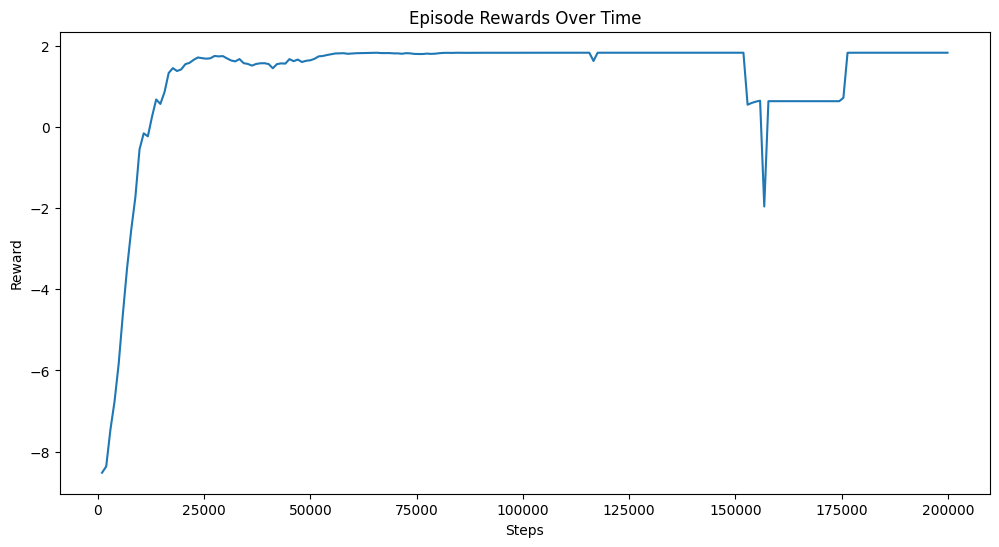

In [58]:
# Plot episode rewards over time
plt.figure(figsize=(12, 6))
plt.plot(episode_rewards.index * 10, episode_rewards.values) # Real step is index * 10
plt.title('Episode Rewards Over Time')
plt.xlabel('Steps')
plt.ylabel('Reward')
plt.show()

이 그래프를 보면 50000 스텝까지는 적극적으로 학습하다가 60000스텝 즈음부터 리워드 값이 안정화가 되고 있다. 특이하게 150,000 스탭 즘에 보상함수가 갑자기 떨어지는 구간이 있는 것을 확인 할 수 있다.

이제 학습한 알고리즘을 가지고 테스트 셋을 돌려 결과가 될지 알아보도록 하겠다. 이때 window size만큼은 train set에서 마지막 데이터들을 가져와서 앞에 붙혀 놓도록 하겠다. 이는 예측하는 범위 자체는 train set이랑 test set이랑 겹치지 않으므로 데이터 누수가 일어나지 않으며 test set의 범위를 더 늘릴 수도 있다는 장점이 있다.

In [77]:
stock_feat_test_env = np.concatenate(
    [stock_feat_train[-WINDOW_SIZE:], stock_feat_test],
    axis=0
)

# 2) stock_news: (T, N, F_news)
stock_news_test_env = np.concatenate(
    [stock_news_train[-WINDOW_SIZE:], stock_news_test],
    axis=0
)

# 3) main_news: (T, F_macro)
main_news_test_env = np.concatenate(
    [main_news_train[-WINDOW_SIZE:], main_news_test],
    axis=0
)

# 4) close_prices: (T, N)
stock_close_prices_test_env = np.concatenate(
    [stock_close_prices_train[-WINDOW_SIZE:], stock_close_prices_test],
    axis=0
)

In [78]:
print(stock_feat_test_env.shape)
print(stock_news_test_env.shape)
print(main_news_test_env.shape)
print(stock_close_prices_test_env.shape)

(103, 1, 7)
(103, 1, 768)
(103, 768)
(103, 2)


In [86]:

test_env = PortfolioEnv(
    stock_feat=stock_feat_test_env,
    stock_news=stock_news_test_env,
    global_news=main_news_test_env,
    close_prices=stock_close_prices_test_env,
    window_size=WINDOW_SIZE,
    trading_cost=0.01,  # 1% 수수료
)
obs, info = test_env.reset()
done = False
total_reward = 0.0


while not done:
    action, _ = model.predict(obs, deterministic=True) # deterministic=True면 탐험 없이 “정책 그 자체” 행동
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    total_reward += reward

print("Episode total reward:", total_reward)
print("Final wealth:", info["wealth"])

Episode total reward: -0.12278576
Final wealth: 0.884453


지금 돌린 셋에서는 오히려 원래 있는 돈을 잃는 결과가 나왔는데. 왜그런지 조금 혼란스럽다. 아무리 과적합이 되었어도 이정도 까지 차이가 날까 싶어서 실제 주식은 어땠는지 확인해 보려 한다.

In [75]:
stock_close_prices_test[-1, 0] / stock_close_prices_test[0, 0]

np.float64(0.8789641159743469)

이를 통해 실제 주식도 떨어지는 와중에 어느정도 방어에 성공했다고 볼 수도 있겠지만 내가 원하는 모델은 떨어질땐 현금화하고 오를땐 주식을 사는 모델이기에 그렇게 만족스럽다 할 수 는 없을 것 같다.

그리고 지금 내가 callback으로 만든 로거가 주는 정보가 생각보다 없어서 이번에는 자체 로거에 설정해서 다시 학습을 시켜보도록 하겠다.

### Training Second Model

In [62]:
class WealthLoggerCallback(BaseCallback):
    """
    기본 로거에 커스텀 지표('wealth')를 추가하는 심플한 콜백
    """
    def _on_step(self) -> bool:
        # 현재 환경의 info 가져오기
        infos = self.locals.get("infos", [{}])[0]
        
        # wealth 정보가 있다면 로거에 기록
        if "wealth" in infos:
            self.logger.record("custom/wealth", infos["wealth"])
            
        return True

In [63]:
from source.portfolio_feature_extractor import PortfolioFeatureExtractor

policy_kwargs = dict(
    features_extractor_class=PortfolioFeatureExtractor,
    features_extractor_kwargs=dict(
        d_model=256,
        n_head=4,
        agent_layers=2,
    ),
    net_arch=dict(pi=[64], vf=[64]),
)

model_v2 = PPO(
    policy="MultiInputPolicy",
    env=env,
    policy_kwargs=policy_kwargs,
    verbose=1,
    seed=42,
    n_steps=2048
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


In [64]:
log_path = "./logs/ppo_portfolio_v2"
new_logger = configure(log_path, ["stdout", "csv"])

# 2. 모델에 로거 부착
model_v2.set_logger(new_logger)

Logging to ./logs/ppo_portfolio_v2


이번에는 전의 그래프에서 확인했던 가장 처음 평지에 오르는 스탭인 700,000언저리까지만 학습을 진행하도록 하겠다.

In [ ]:
# total_timesteps = 700_000
# model_v2.learn(total_timesteps=total_timesteps, callback=WealthLoggerCallback())

# model_v2.save("./models/portfolio_ppo_v2")

----------------------------------
| custom/            |           |
|    wealth          | 0.6671399 |
| rollout/           |           |
|    ep_len_mean     | 1.96e+03  |
|    ep_rew_mean     | -8.33     |
| time/              |           |
|    fps             | 165       |
|    iterations      | 1         |
|    time_elapsed    | 12        |
|    total_timesteps | 2048      |
----------------------------------
------------------------------------------
| custom/                 |              |
|    wealth               | 0.45832407   |
| rollout/                |              |
|    ep_len_mean          | 1.96e+03     |
|    ep_rew_mean          | -8.38        |
| time/                   |              |
|    fps                  | 105          |
|    iterations           | 2            |
|    time_elapsed         | 38           |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0066598523 |
|    clip_fraction   

드디어 221분간의 학습이 완료되었고, 이걸 다시해야하는 참사를 막기위해 평가는 파일을 불러와서 하도록 하겠다.

In [83]:
model_v2 = PPO.load("./models/portfolio_ppo_v2")

In [145]:

obs, info = test_env.reset()
done = False
total_reward = 0.0


while not done:
    action, _ = model_v2.predict(obs, deterministic=True) # deterministic=True면 탐험 없이 “정책 그 자체” 행동
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    total_reward += reward

print("Episode total reward:", total_reward)
print("Final wealth:", info["wealth"])

Episode total reward: -0.1137198
Final wealth: 0.89250815


지금 완벽하게 동일한 결과가 나왔다. 비상이다. 일단 무슨일인지 파악해보도록하겠다.

In [144]:
# 테스트 환경 리셋
obs, _ = test_env.reset()

# 두 모델의 행동 예측
action_v1, _ = model.predict(obs, deterministic=True)
action_v2, _ = model_v2.predict(obs, deterministic=True)

print(f"Model V1 Raw Action: {action_v1[:5]}") # 앞부분만 출력
print(f"Model V2 Raw Action: {action_v2[:5]}")

# Softmax 변환 (실제 투자 비중)
def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

weight_v1 = softmax(action_v1)
weight_v2 = softmax(action_v2)

print("-" * 30)
print(f"Model V1 Weights: {weight_v1[:5]}")
print(f"Model V2 Weights: {weight_v2[:5]}")


Model V1 Raw Action: [ 1. -1.]
Model V2 Raw Action: [ 1. -1.]
------------------------------
Model V1 Weights: [0.880797   0.11920292]
Model V2 Weights: [0.880797   0.11920292]


우려하던 일이 벌어지고야 말았다. 그냥 애플에 주식 넣으면 무조건 떡상한다는 것을 배우고서는 최대한 애플에 몰아주는걸 학습해버린 것이다. 일단 이것이 주식의 수수료가 너무 높아서 그럴 수도 있을 것 같아 일단 주식 거래의 수수료를 낮춰서 다시 학습해보기로 했다.

### Train Third Model

이번에는 수수료를 대폭 낮춰 0.1프로의 수수료로 하고 나머지는 같은 웨이트로 진행하도록 하겠다.

In [97]:
env = PortfolioEnv(
    stock_feat=stock_feat_train,
    stock_news=stock_news_train,
    global_news=main_news_train,
    close_prices=stock_close_prices_train,
    window_size=WINDOW_SIZE,
    trading_cost=0.001,  # 0.1% 수수료
)

In [107]:
from source.portfolio_feature_extractor import PortfolioFeatureExtractor

policy_kwargs = dict(
    features_extractor_class=PortfolioFeatureExtractor,
    features_extractor_kwargs=dict(
        d_model=256,
        n_head=4,
        agent_layers=2,
    ),
    # 백본이 이미 복잡하니까 머리 MLP는 간단하게:
    net_arch=dict(pi=[64], vf=[64]),
)

model_v3 = PPO(
    policy="MultiInputPolicy",
    env=env,
    policy_kwargs=policy_kwargs,
    verbose=1,
    seed=42,
    n_steps=2048
)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


그리고 좀더 나은 로거 정보를 모으기 위해 에피소드가 끝났을때 wealth를 저장해주도록 하겠다.

In [ ]:
class BetterWealthLoggerCallback(BaseCallback):
    def _on_step(self) -> bool:
        # 현재 환경의 info 가져오기
        infos = self.locals.get("infos", [{}])[0]
        
        # wealth 정보가 있다면 로거에 기록
        if "episode" in infos:
            self.logger.record_mean("custom/final_wealth", infos["wealth"])
            
        return True

In [ ]:
log_path = "./logs/ppo_portfolio_v3"
new_logger = configure(log_path, ["stdout", "csv"])

# 2. 모델에 로거 부착
# model_v3.set_logger(new_logger)

Logging to ./logs/ppo_portfolio_v3


In [ ]:
# total_timesteps = 700_000
# model_v3.learn(total_timesteps=total_timesteps, callback=BetterWealthLoggerCallback())

# model_v3.save("./models/portfolio_ppo_v3")

---------------------------------
| custom/            |          |
|    final_wealth    | 1.3      |
| rollout/           |          |
|    ep_len_mean     | 1.96e+03 |
|    ep_rew_mean     | 0.262    |
| time/              |          |
|    fps             | 141      |
|    iterations      | 1        |
|    time_elapsed    | 14       |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| custom/                 |              |
|    final_wealth         | 1.31         |
| rollout/                |              |
|    ep_len_mean          | 1.96e+03     |
|    ep_rew_mean          | 0.265        |
| time/                   |              |
|    fps                  | 95           |
|    iterations           | 2            |
|    time_elapsed         | 42           |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0066564437 |
|    clip_fraction        | 0.050

#### Evaluation

175분간의 학습이 끝나고 이제 저장된 파일을 로드하여 어떻게 학습이 되었을지 확인해 보도록 하겠다.

In [ ]:
model_v3 = PPO.load("./models/portfolio_ppo_v3")

In [113]:
test_env = PortfolioEnv(
    stock_feat=stock_feat_test_env,
    stock_news=stock_news_test_env,
    global_news=main_news_test_env,
    close_prices=stock_close_prices_test_env,
    window_size=WINDOW_SIZE,
    trading_cost=0.001,  # 0.1% 수수료
)
obs, info = test_env.reset()
done = False
total_reward = 0.0


while not done:
    action, _ = model_v3.predict(obs, deterministic=True) # deterministic=True면 탐험 없이 “정책 그 자체” 행동
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    total_reward += reward

print("Episode total reward:", total_reward)
print("Final wealth:", info["wealth"])

Episode total reward: -0.103354834
Final wealth: 0.90180695


다행히 이번에는 이전 모델들과는 다른 결과가 나왔다. 이제 그래프를 통해 학습이 어떻게 진행되었는지 확인해 보도록 하겠다.

In [116]:
model_v3_log = pd.read_csv("./logs/ppo_portfolio_v3/progress.csv")
model_v3_log

,time/fps,time/time_elapsed,time/iterations,custom/final_wealth,rollout/ep_rew_mean,time/total_timesteps,rollout/ep_len_mean,train/std,train/policy_gradient_loss,train/learning_rate,train/clip_range,train/n_updates,train/loss,train/entropy_loss,train/approx_kl,train/explained_variance,train/value_loss,train/clip_fraction
0,141,14,1,1.299008,0.261601,2048,1960.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,95,42,2,1.307199,0.264744,4096,1960.0,0.982346,-0.002352,0.0003,0.2,10.0,-0.014952,-2.815792,0.006656,-0.005316,0.036116,0.050879
2,86,71,3,1.570114,0.326879,6144,1960.0,0.964075,-0.003170,0.0003,0.2,20.0,-0.006726,-2.781278,0.008188,0.000023,0.003505,0.062061
3,83,98,4,1.197911,0.290304,8192,1960.0,0.952594,-0.001399,0.0003,0.2,30.0,-0.000689,-2.751696,0.004490,0.000026,0.002880,0.038477
4,76,134,5,1.052956,0.242563,10240,1960.0,0.942185,-0.000384,0.0003,0.2,40.0,-0.003643,-2.726177,0.004971,0.000031,0.002096,0.024121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,66,10379,338,5.096301,1.664495,692224,1960.0,0.405987,0.010631,0.0003,0.2,3370.0,-0.012865,-1.032854,0.316586,0.067185,0.001882,0.304199
338,66,10405,339,4.790760,1.662675,694272,1960.0,0.409107,0.017940,0.0003,0.2,3380.0,0.022631,-1.037073,0.279733,0.033200,0.001855,0.276172
339,66,10442,340,5.077145,1.662204,696320,1960.0,0.407302,0.012551,0.0003,0.2,3390.0,-0.024561,-1.039552,0.329609,0.030441,0.002078,0.281885
340,66,10478,341,4.860965,1.661621,698368,1960.0,0.406201,0.019890,0.0003,0.2,3400.0,-0.020198,-1.032156,0.329218,0.041670,0.001895,0.305811


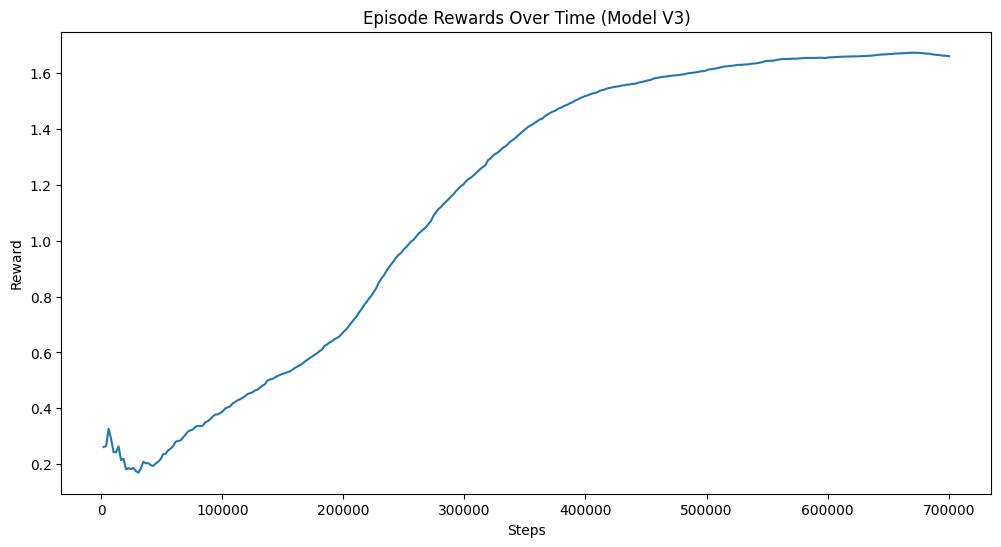

In [121]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['rollout/ep_rew_mean']) # Real step is iterations * 2048
plt.title('Episode Rewards Over Time (Model V3)')
plt.xlabel('Steps')
plt.ylabel('Reward')
plt.show()

지금 리워드는 전체적으로 무난한 그래프 그림을 그리고 있는듯 하다. 하지만 내가 원하지 않는 곳에서 수렴을 하려는 상황이라 분명히 어딘가 잘못된 상황이 있는 것이 확실하기에 좀더 그래프를 살펴봐야 할 것 같다.

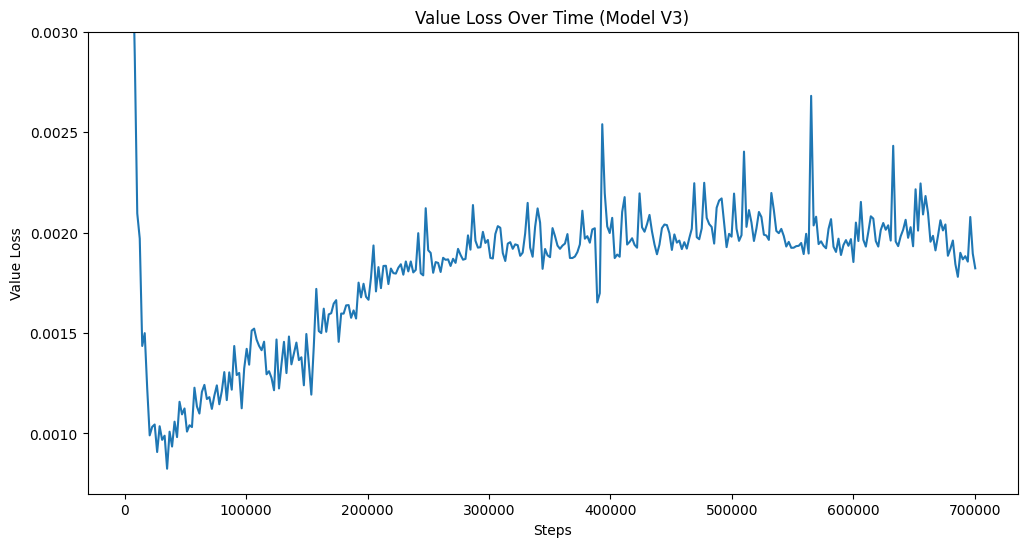

In [128]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/value_loss']) # Real step is iterations * 2048
plt.ylim(0.0007, 0.003)
plt.title('Value Loss Over Time (Model V3)')
plt.xlabel('Steps')
plt.ylabel('Value Loss')
plt.show()

Value Loss도 제대로 하지 줄이지 못하고 횡보하면서 올라가는 모습을 보면 제대로 학습을 하지 못한다는 느낌이 든다. 하지만 정확하게 파악할수는 없으므로 Policy Gradient Loss를 확인해 보도록 하겠다.

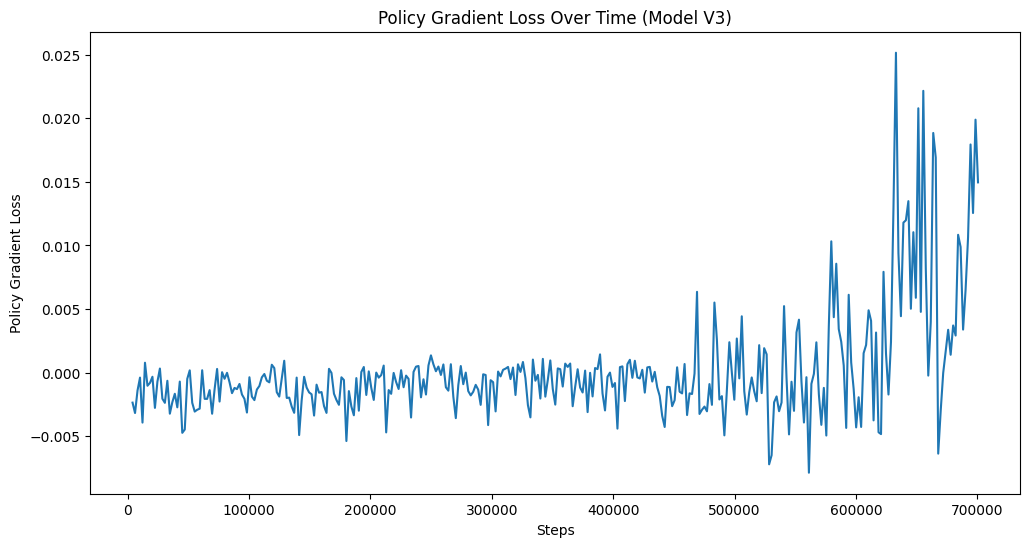

In [134]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/policy_gradient_loss']) # Real step is iterations * 2048
plt.title('Policy Gradient Loss Over Time (Model V3)')

plt.xlabel('Steps')
plt.ylabel('Policy Gradient Loss')
plt.show()

이 그래프에서 이번 학습이 제대로 진행되지 않았다는 것을 확인 가능하다. 지금 450,000 스텝즈음 부터 Loss의 변동이 점점 커지면서 절댓값도 커지는 것을 볼수 있는데, 이는 모델이 정책을 업데이트 할때 이전에 비해 과도하게 업데이트 하려하고 있다는 것을 확인 할 수 있는 그래프로 확인 가능하다. 이를 좀더 확실하게 확인하기 위해 KL값도 확인해 보도록 하겠다.

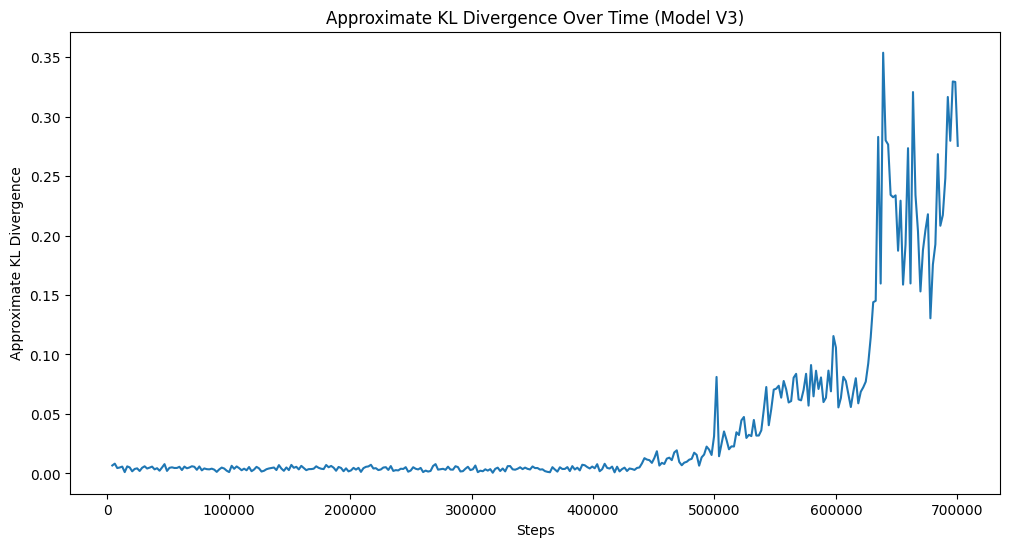

In [135]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/approx_kl']) # Real step is iterations * 2048
plt.title('Approximate KL Divergence Over Time (Model V3)')

plt.xlabel('Steps')
plt.ylabel('Approximate KL Divergence')
plt.show()

내가 예상한대로 나와준 것 같다. 지금 정책이 실제로 변화한 크기를 의미하는 KL값이 450,000스텝 즘부터 값이 폭발하기 시작하면서 모델이 갈피를 제대로 못잡고 정책이 확확 변하고 있다는 것을 확인 가능하다.

마지막으로 전체 로스값이 어떻게 변화는지 확인해 보도록 하겠다.

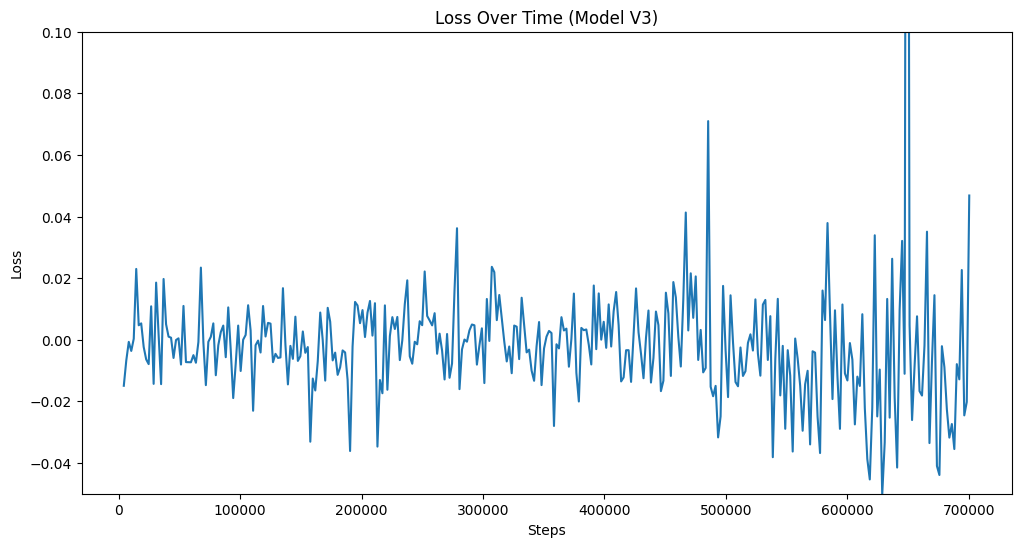

In [136]:
# Plot reward over time
plt.figure(figsize=(12, 6))
plt.plot(model_v3_log['time/iterations'] * 2048, model_v3_log['train/loss']) # Real step is iterations * 2048
plt.title('Loss Over Time (Model V3)')
plt.ylim(-0.05, 0.1)
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.show()

지금 전체 Loss Graph의 모양을 보면 그냥 특별한 변화 없이 횡보하는 모습을 보이면서 엑터의 학습은 제대로 되는것 처럼 보이지만 크리틱의 학습이 제대로 되는지에 대해서는 의문이 드는 상태이다.

## Conclusion

지금 전체적인 그래프의 상황을 보면 모델이 pleateu를 발견하고 거기에서 빠져나가지 못하면서 정책들이 거의 고정되고, 이로인해 여러 값들이 튀고 있다고 생각된다. 하지만 진정한 최적의 값은 이곳에 있지 않다고 생각되는데, 단순하게 생각해도 애플의 주식은 train 기간동안 9.3배 상승 했는데 현재 reward를 보면 현재 e^1.6 = 4.95 배의 수익률만 내면서 기대에 못미치는 수익률을 보였기 때문이다. 지금 최대로 살수 있는 비율이 정해져 있다는 것을 감안 하더라도 떨어질때 팔고 올라갈때 살수 있음을 생각해 보면 이는 많이 아쉬운 결과를 확인 가능하다.

In [142]:
apple_close_prices_train[-1] / apple_close_prices_train[0] # Train 기간 동안 주가 상승률

array([9.32251094])

전체적으로 상승하는 애플의 주식으로 인해 그냥 애플에 집어넣고 있으면 이득을 본다는 것을 발견하고 그 이상의 탐험은 거부하는 모습을 강하게 보인다. 그리고 지금 action의 범위를 [-1, 1] 로 제한을 해놔서 SoftMax함수를 사용했을때 주식이 한곳에 쏠리는 것을 막게 하고 있는데, 지금은 두가지 옵션 밖에 없어서 그런 옵션도 그저 별 효과를 발하지 못하고 그냥 애플에 최대한의 돈을 몰아넣고 있는 모습을 보인다.

### Future Work

이와같은 분석으로 볼때 역시 더많은 데이터와 더 많은 주식 투자 옵션을 모델에게 제공해야 한다는 것이 절실해 보인다. 애초에 이 모델은 여러개의 주식을 받아와서 분석하기 위해 설계한 모델이므로 단 하나의 주식을 예측하고 포트폴리오를 짜는데에는 최적화 되지 않은 결과를 보일 수 밖에 없을 것 같다. 현재는 데이터 크롤링의 어려움으로 인해 애플 주식 데이터와 뉴스데이터 하나밖에 파악하지 못했지만, 더 많은 주식 종목과 데이터가 추가된다면 훨씬 나은 결과를 내줄 것이라 기대한다. 하지만 이때 조심해야하는 점이 더 있는데, 입력 차원이 늘어남으로서 필요로 하는 데이터의 갯수가 더 늘어날 가능성이 높은데, 지금 모은 8년의 데이터가 충분할지 확실하지 않다. 하지만 더 이전의 데이터를 얻기는 정말 힘든데, 구글 뉴스를 제외한 대부분의 뉴스 데이터 프로바이더가 2010년대 후반이후 부터의 데이터만 지원하기에 내가 원하는 데이터를 얻을 수 있을 지 잘 모르겠다.

그리고 데이터의 정제도 더 중요해 질 수도 있다. 지금 news data는 데이터의 갯수가 너무 많아 뉴스데이터를 받아와 크롤링 하기에는 불가능에 가까워 제목을 임베딩 했는데, 지금 제목의 길이가 일정 이상인 것으로 필터링 하긴 했지만 그렇다고 해서 그것이 의미있는 제목일 것이라는 보장은 없다. 그리고 임베딩의 방법도 지금은 구글의 임베딩을 사용하였지만, 그것이 현재 SOTA급 성능을 보여준다 하더라도 주식에 특화된 임베딩은 아니기에 모델이 구분하기에 힘들어 할 수도 있다. 그리고 애플의 뉴스 데이터도 GDELT에서 키워드를 이용하여 크롤링을 해왔지만 그 데이터가 주식과 연관된 데이터라는 보장은 없고, 단순히 아이폰 사용팁 같은 저널을 긁어 왔을때 이와 같은 정보가 임베딩을 오염시켰을 가능성이 높다. yfinance에서 제공하는 뉴스 데이터를 활용할 수 있다면 더 나은 양질의 데이터를 확보할 수 있을 가능성이 높을 것 같다. 하지만 그것이 제공하는 뉴스의 양이 내가 필요한 양이 있는지는 확실하지 않다.